# K-Means, scaling, and alternative clustering

This is an exploratory fit to a fixed song collection, not an out-of-sample prediction experiment. Genre labels are reserved for a post-hoc comparison and **never included as numeric inputs**. Cluster IDs have no inherent relation to genre IDs, so we use adjusted Rand index (ARI), not direct label equality.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

raw = pd.read_csv("../../../5-Clustering/data/nigerian-songs.csv")
genres = ["afro dancehall", "afropop", "nigerian pop"]
songs = raw.loc[raw.artist_top_genre.isin(genres) & raw.popularity.gt(0)].copy()
print(f"Raw songs: {len(raw)}; retained: {len(songs)}")
assert not songs.isna().any().any()
assert songs.index.is_unique
print(songs.artist_top_genre.value_counts())


Raw songs: 530; retained: 286
artist_top_genre
afro dancehall    206
afropop            61
nigerian pop       19
Name: count, dtype: int64


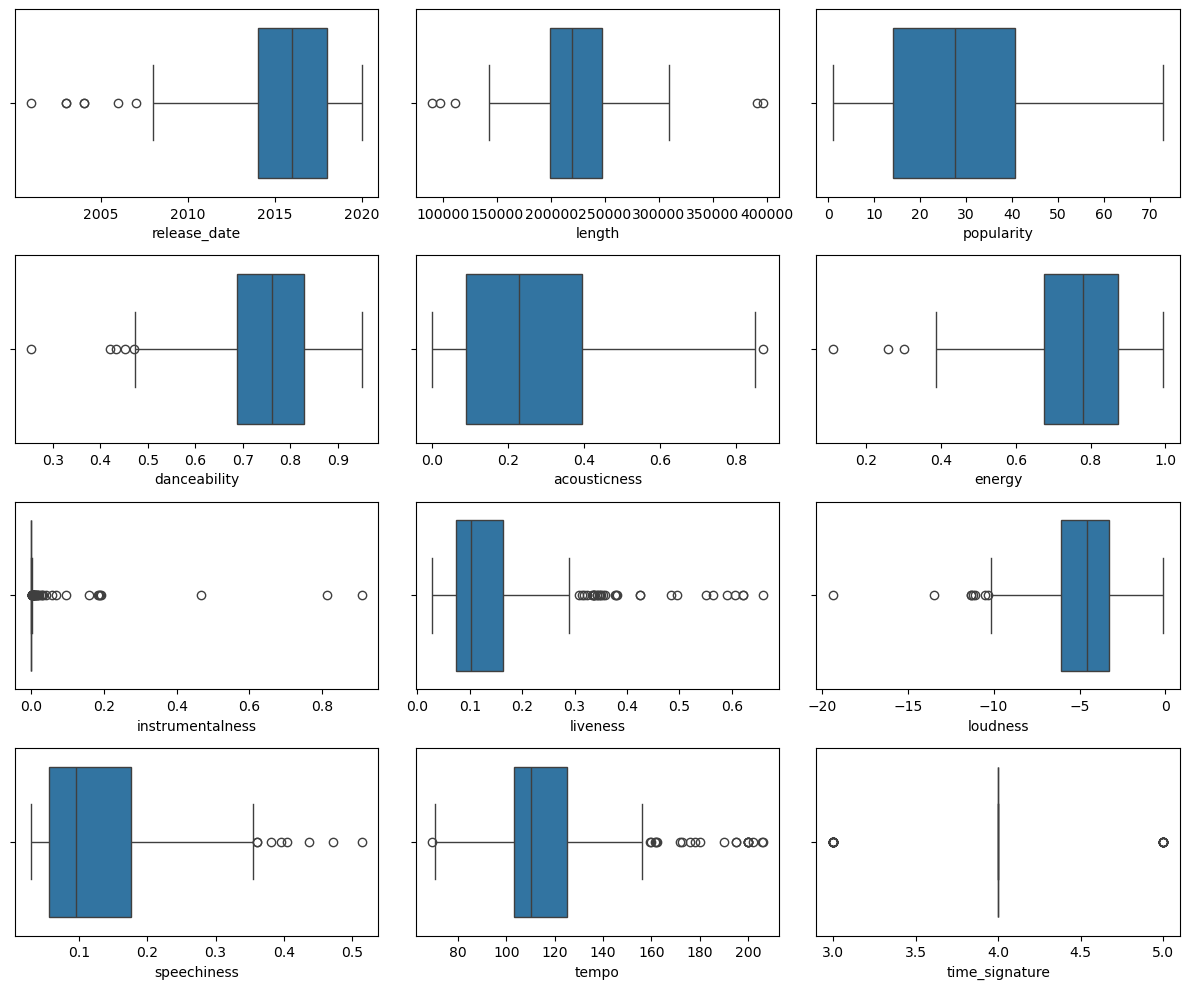

In [2]:
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
features = ["popularity", "danceability", "acousticness", "loudness", "energy"]
X = songs[features]
fig, axes = plt.subplots(4, 3, figsize=(12, 10))
for ax, column in zip(axes.flat, songs.select_dtypes("number").columns):
    sns.boxplot(data=songs, x=column, ax=ax)
fig.tight_layout()
plt.show()
scaled = StandardScaler().fit_transform(X)
assert np.isfinite(scaled).all()
assert "artist_top_genre" not in X.columns

,Representation,k,Inertia,Silhouette
0,raw,1,91283.9260,NaN
1,raw,2,28531.6496,0.5644
2,raw,3,12998.6603,0.5495
3,raw,4,8493.3664,0.5086
4,raw,5,5891.3057,0.4841
5,raw,6,4479.6991,0.4650
6,raw,7,3874.9646,0.4270
7,raw,8,3357.7010,0.4137
8,raw,9,2963.6288,0.3946
9,raw,10,2697.2434,0.4048


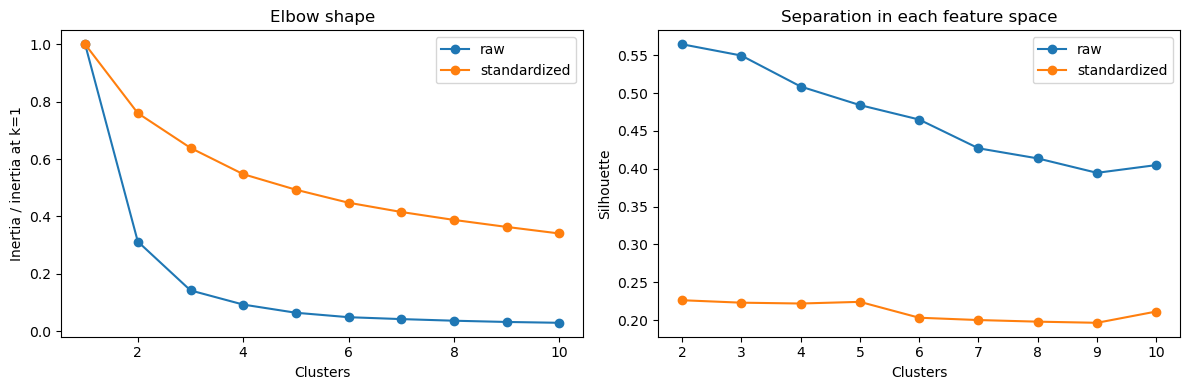

In [3]:
rows = []
for representation, values in [("raw", X), ("standardized", scaled)]:
    for k in range(1, 11):
        model = KMeans(n_clusters=k, n_init=20, random_state=42).fit(values)
        rows.append({"Representation": representation, "k": k, "Inertia": model.inertia_, "Silhouette": silhouette_score(values, model.labels_) if k > 1 else np.nan})
results = pd.DataFrame(rows)
display(results.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for representation in ["raw", "standardized"]:
    part = results[results.Representation == representation]
    # Separate normalization allows shape comparison, not absolute inertia comparison.
    axes[0].plot(part.k, part.Inertia / part.Inertia.iloc[0], marker="o", label=representation)
    axes[1].plot(part.k, part.Silhouette, marker="o", label=representation)
axes[0].set(xlabel="Clusters", ylabel="Inertia / inertia at k=1", title="Elbow shape")
axes[1].set(xlabel="Clusters", ylabel="Silhouette", title="Separation in each feature space")
for ax in axes: ax.legend()
fig.tight_layout()
plt.show()

## Three clusters and scaling challenge

A high raw-space silhouette may simply reflect popularity’s larger numerical scale. Standardizing gives every feature unit variance; it can lower silhouette while producing a more balanced distance definition. Scores from different representations do not measure an identical geometry. Three genres do not require three discovered groups.

,Silhouette,Genre ARI
Representation,,
raw,0.5495,0.0179
standardized,0.2232,0.0958
robust scaled,0.1912,0.0738
standardized audio only,0.2457,0.0399


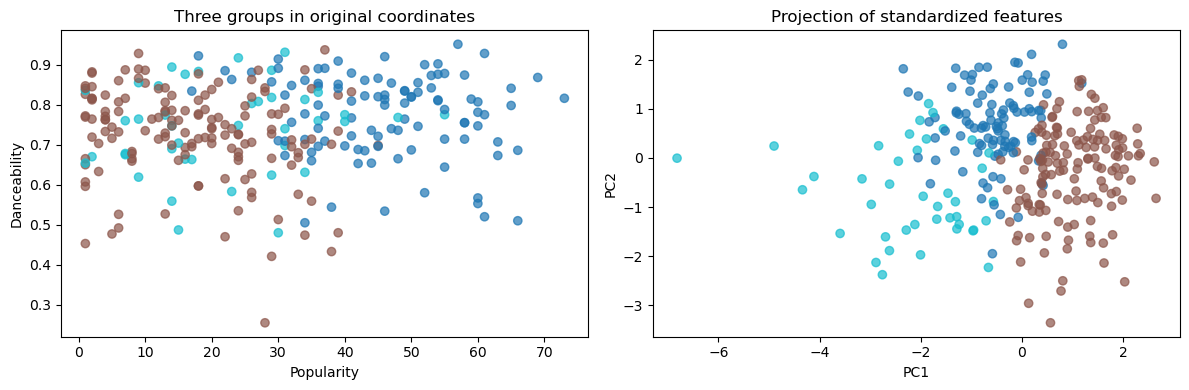

,popularity,danceability,acousticness,loudness,energy
cluster,,,,,
0,45.892,0.776,0.265,-5.210,0.719
1,17.413,0.725,0.216,-3.648,0.855
2,21.634,0.743,0.435,-8.644,0.542


artist_top_genre,afro dancehall,afropop,nigerian pop
row_0,,,
0,66,30,6
1,119,22,2
2,21,9,11


Seed stability ARI: [1. 1. 1. 1. 1.]


In [4]:
comparisons = []
representations = {"raw": X.to_numpy(), "standardized": scaled,
                   "robust scaled": RobustScaler().fit_transform(X),
                   "standardized audio only": StandardScaler().fit_transform(X.drop(columns="popularity"))}
for name, values in representations.items():
    fitted = KMeans(n_clusters=3, n_init=20, random_state=42).fit(values)
    comparisons.append({"Representation": name, "Silhouette": silhouette_score(values, fitted.labels_), "Genre ARI": adjusted_rand_score(songs.artist_top_genre, fitted.labels_)})
display(pd.DataFrame(comparisons).set_index("Representation").round(4))
kmeans = KMeans(n_clusters=3, n_init=20, random_state=42).fit(scaled)
projection = PCA(n_components=2).fit_transform(scaled)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(songs.popularity, songs.danceability, c=kmeans.labels_, cmap="tab10", alpha=.7)
axes[0].set(xlabel="Popularity", ylabel="Danceability", title="Three groups in original coordinates")
axes[1].scatter(projection[:,0], projection[:,1], c=kmeans.labels_, cmap="tab10", alpha=.7)
axes[1].set(xlabel="PC1", ylabel="PC2", title="Projection of standardized features")
fig.tight_layout()
plt.show()
display(songs.assign(cluster=kmeans.labels_).groupby("cluster")[features].mean().round(3))
display(pd.crosstab(kmeans.labels_, songs.artist_top_genre))
permuted = (kmeans.labels_ + 1) % 3
assert adjusted_rand_score(kmeans.labels_, permuted) == 1
stability = [adjusted_rand_score(kmeans.labels_, KMeans(n_clusters=3, n_init=20, random_state=seed).fit_predict(scaled)) for seed in range(5)]
print("Seed stability ARI:", np.round(stability, 3))

## Assignment alternative 1 — agglomerative clustering on songs

Ward linkage merges groups to limit the increase in within-cluster squared deviations. It has no random centroid initialization and offers a hierarchy, but still favors compact Euclidean groups. We compare three groups on exactly the same standardized songs. The genre cross-tab is descriptive, not training supervision.

Ward silhouette: 0.1969
Ward genre ARI: 0.05
Ward versus K-Means ARI: 0.5599


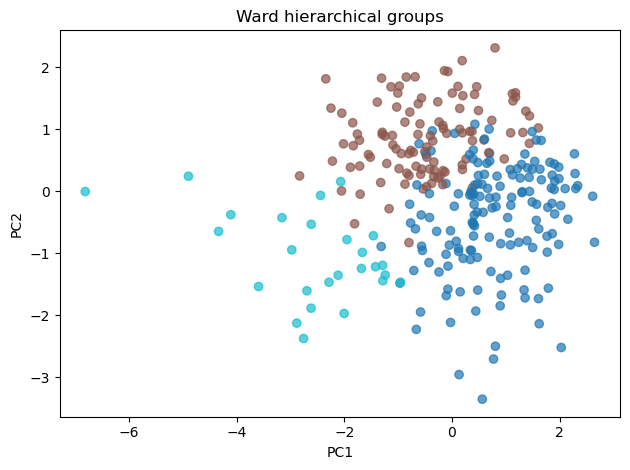

In [5]:
hierarchical = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(scaled)
print("Ward silhouette:", round(silhouette_score(scaled, hierarchical), 4))
print("Ward genre ARI:", round(adjusted_rand_score(songs.artist_top_genre, hierarchical), 4))
print("Ward versus K-Means ARI:", round(adjusted_rand_score(kmeans.labels_, hierarchical), 4))
plt.scatter(projection[:,0], projection[:,1], c=hierarchical, cmap="tab10", alpha=.7)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Ward hierarchical groups")
plt.tight_layout(); plt.show()

## Assignment alternative 2 — DBSCAN on curved synthetic groups

Source: Scikit-learn `make_moons`, generated below with a fixed seed. This controlled example explains a case where centroid partitions are a poor match. DBSCAN joins density-connected neighborhoods and labels isolated points as noise. `eps` is a distance radius; `min_samples` sets the core-density requirement. Ground-truth labels are used only afterward for a diagnostic comparison.

,eps,Clusters,Noise,ARI,Silhouette without noise
0,0.08,17,35,0.124,0.4523
1,0.15,2,1,0.995,0.3261
2,0.30,2,0,1.000,0.3255


DBSCAN ARI: 0.9950124376554706
K-Means ARI: 0.24811860052823909


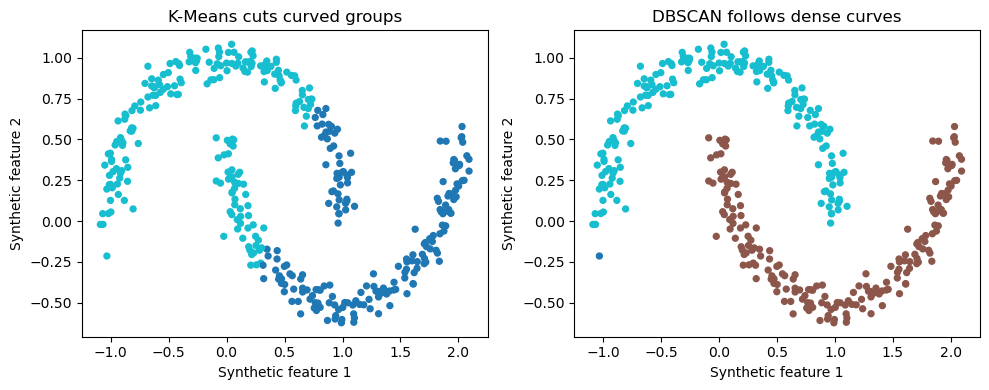

In [6]:
from sklearn.datasets import make_moons
moons, truth = make_moons(n_samples=400, noise=.06, random_state=42)
moon_rows = []
for eps in [.08, .15, .3]:
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(moons)
    non_noise = labels != -1
    n_clusters = len(set(labels) - {-1})
    score = silhouette_score(moons[non_noise], labels[non_noise]) if 1 < n_clusters < non_noise.sum() else np.nan
    moon_rows.append({"eps": eps, "Clusters": n_clusters, "Noise": int((~non_noise).sum()), "ARI": adjusted_rand_score(truth, labels), "Silhouette without noise": score})
display(pd.DataFrame(moon_rows).round(4))
db_labels = DBSCAN(eps=.15, min_samples=5).fit_predict(moons)
km_labels = KMeans(n_clusters=2, n_init=20, random_state=42).fit_predict(moons)
print("DBSCAN ARI:", adjusted_rand_score(truth, db_labels))
print("K-Means ARI:", adjusted_rand_score(truth, km_labels))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, labels, title in zip(axes, [km_labels, db_labels], ["K-Means cuts curved groups", "DBSCAN follows dense curves"]):
    ax.scatter(moons[:,0], moons[:,1], c=labels, cmap="tab10", s=18)
    ax.set(title=title, xlabel="Synthetic feature 1", ylabel="Synthetic feature 2")
fig.tight_layout(); plt.show()
assert adjusted_rand_score(truth, db_labels) > .9
assert len(db_labels) == len(moons)

## Interpretation

The synthetic comparison tests geometry, not a claim that DBSCAN wins on every dataset. Too small a radius fragments groups and marks many points as noise; too large a radius can merge the moons. Silhouette can prefer convex partitions even when curved groups match known structure better. On songs, compare internal cohesion, stability, and meaningful summaries rather than demanding exact genre recovery. Existing genre labels are not ground truth for every possible audio grouping. See answers.md for the numerical findings and limitations.